In [5]:
from tqdm.auto import tqdm
import pandas as pd
import json
from collections import Counter

# Clustering & classification
import hdbscan
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder

In [32]:
import numpy as np

In [4]:
from processing import prepare_text, extract_keywords, embed_texts, analyze_sentiment

def get_keywords_per_cluster(
    df,
    keywords_col="keywords",
    cluster_col="cluster_id",
    top_n=10
):
    """
    Returns a DataFrame:
    cluster_id | top_keywords
    """

    results = []

    # Ignore HDBSCAN noise
    clusters = sorted(c for c in df[cluster_col].unique() if c != -1)

    for cluster_id in clusters:
        cluster_rows = df[df[cluster_col] == cluster_id]

        # Flatten all keyword lists in this cluster
        all_keywords = []
        for kws in cluster_rows[keywords_col]:
            if isinstance(kws, list):
                all_keywords.extend(kws)

        if not all_keywords:
            continue

        # Count keyword frequency
        counter = Counter(all_keywords)

        top_keywords = [
            kw for kw, _ in counter.most_common(top_n)
        ]

        results.append({
            "cluster_id": cluster_id,
            "top_keywords": top_keywords
        })

    return pd.DataFrame(results)

In [7]:
# ================= LOAD DATA ================= #
df = pd.read_csv("dawn_content.csv")
# df2 = pd.read_csv("dawn_links.csv")

# df = pd.merge(df1, df2, on="id", how="left", suffixes=("", "_y"))

df = df.rename(columns={"text": "content"})
df = df[["id", "title", "content", "date", "location"]]  # "id", "title", "content", "url", "date", "location"

df["date"] = pd.to_datetime(df["date"])
df = df[df["date"].dt.year == 2024]

tqdm.pandas()

In [12]:
from processing import prepare_text, extract_keywords, embed_texts, analyze_sentiment

In [13]:
# ---- Step 1: Prepare text (ALL rows) ----
df["text"] = df.progress_apply(
    lambda r: prepare_text(r["title"], r["content"]),
    axis=1
)

100%|██████████| 22425/22425 [00:00<00:00, 51872.03it/s]


In [14]:
# ---- Step 2: Keywords (FIRST 20,000 rows ONLY) ----
df["keywords"] = None

# N_KEYWORDS = 20_000

df["keywords"] = df["text"].progress_apply(extract_keywords)

# ---- Step 3: Embeddings (ALL rows, unchanged) ----
embeddings = embed_texts(df["text"].tolist())

Batches: 100%|██████████| 351/351 [20:49<00:00,  3.56s/it]


In [33]:
# ---- Step 3: Embeddings (ALL rows, unchanged) ----
embeddings = embed_texts(df["text"].tolist())

np.save("embeddings.npy", embeddings)

Batches: 100%|██████████| 351/351 [19:47<00:00,  3.38s/it]


In [28]:
from sklearn.cluster import AgglomerativeClustering, HDBSCAN
from sklearn.preprocessing import normalize

In [ ]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5,
    metric='cosine',
    cluster_selection_method='eom'
)

df['labels'] = clusterer.fit_predict(embeddings)
df['labels'].value_counts()

In [34]:
clusterer = AgglomerativeClustering(
    n_clusters=None,
    metric="cosine",
    linkage="average",
    distance_threshold=0.3
)

labels = clusterer.fit_predict(embeddings)

df['labels'] = labels

df["labels"].value_counts()

labels
849     295
252     153
36      142
697     131
162     130
       ... 
5773      1
4393      1
7127      1
4102      1
3599      1
Name: count, Length: 7357, dtype: int64

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50)
embeddings_reduced = pca.fit_transform(embeddings)

labels
20    1257
0     1131
5     1062
8     1007
15    1003
1      998
12     915
16     843
9      842
21     842
6      781
11     773
3      754
28     738
19     726
14     657
26     631
10     620
24     598
2      594
22     560
30     496
17     476
4      473
7      447
13     447
32     439
33     429
18     368
23     332
29     322
27     309
31     278
25     277
Name: count, dtype: int64

In [40]:
clusterer = AgglomerativeClustering(
    n_clusters=28,
    metric="euclidean",
    linkage="ward",
)
labels = clusterer.fit_predict(embeddings_reduced)

df['labels'] = labels

df["labels"].value_counts()

labels
4     1503
0     1464
2     1344
1     1277
20    1257
5     1131
9     1121
12    1062
15    1003
8      998
19     842
21     842
6      781
23     773
3      771
7      754
26     631
24     598
11     594
22     560
17     476
10     473
16     447
13     447
18     368
14     322
27     309
25     277
Name: count, dtype: int64

In [38]:
clusterer = AgglomerativeClustering(
    n_clusters=None,
    metric="euclidean",
    linkage="ward",
    distance_threshold=0.3
)
labels = clusterer.fit_predict(embeddings_reduced)

df['labels'] = labels

df["labels"].value_counts()

labels
1025     13
4383     13
29       12
2474     11
1056     11
         ..
4707      1
10291     1
14323     1
12768     1
6809      1
Name: count, Length: 18179, dtype: int64

In [36]:
df.to_csv(
    "midway.csv",
    index=False,
    encoding='utf-8',
    chunksize=10_000
)

{'icoord': [[5.0, 5.0, 15.0, 15.0],
  [25.0, 25.0, 35.0, 35.0],
  [10.0, 10.0, 30.0, 30.0],
  [45.0, 45.0, 55.0, 55.0],
  [65.0, 65.0, 75.0, 75.0],
  [50.0, 50.0, 70.0, 70.0],
  [20.0, 20.0, 60.0, 60.0],
  [85.0, 85.0, 95.0, 95.0],
  [105.0, 105.0, 115.0, 115.0],
  [90.0, 90.0, 110.0, 110.0],
  [125.0, 125.0, 135.0, 135.0],
  [145.0, 145.0, 155.0, 155.0],
  [130.0, 130.0, 150.0, 150.0],
  [100.0, 100.0, 140.0, 140.0],
  [40.0, 40.0, 120.0, 120.0],
  [165.0, 165.0, 175.0, 175.0],
  [185.0, 185.0, 195.0, 195.0],
  [170.0, 170.0, 190.0, 190.0],
  [205.0, 205.0, 215.0, 215.0],
  [225.0, 225.0, 235.0, 235.0],
  [210.0, 210.0, 230.0, 230.0],
  [180.0, 180.0, 220.0, 220.0],
  [245.0, 245.0, 255.0, 255.0],
  [265.0, 265.0, 275.0, 275.0],
  [250.0, 250.0, 270.0, 270.0],
  [285.0, 285.0, 295.0, 295.0],
  [305.0, 305.0, 315.0, 315.0],
  [290.0, 290.0, 310.0, 310.0],
  [260.0, 260.0, 300.0, 300.0],
  [200.0, 200.0, 280.0, 280.0],
  [80.0, 80.0, 240.0, 240.0],
  [325.0, 325.0, 335.0, 335.0],
  [345

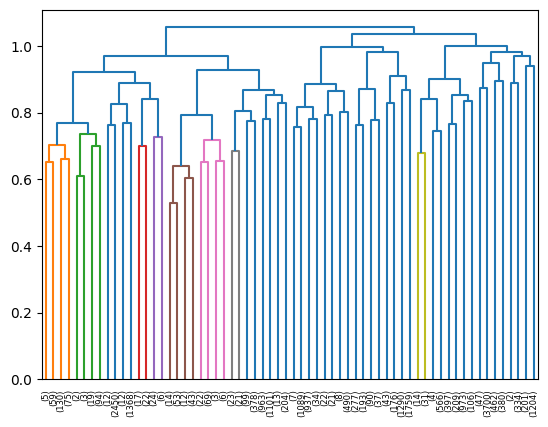

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(embeddings_reduced, method="average", metric="cosine")
from scipy.cluster.hierarchy import fcluster

# Option 1: specify a distance threshold
max_distance = 0.3  # tune based on embeddings
labels = fcluster(Z, t=max_distance, criterion="distance")

dendrogram(Z, truncate_mode="level", p=5)

In [ ]:
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import fcluster

for k in range(2, 100):
    labels = fcluster(Z, t=k, criterion="maxclust")
    score = silhouette_score(embeddings_reduced, labels, metric="cosine")
    print(k, score) # best: 10, 44, 53

2 0.10489348322153091
3 0.10774650424718857
4 0.0999060794711113
5 0.11269271373748779
6 0.1070956364274025
7 0.10117599368095398
8 0.09194622188806534
9 0.10894139111042023
10 0.11178616434335709
11 0.10687413811683655
12 0.10172140598297119
13 0.1022755354642868
14 0.10189936310052872
15 0.10684182494878769
16 0.10480411350727081
17 0.09574861824512482
18 0.08963783085346222
19 0.08457273989915848
20 0.07370827347040176
21 0.07850658148527145
22 0.0739036574959755
23 0.07131131738424301
24 0.07193169742822647
25 0.08049727976322174
26 0.07841901481151581
27 0.07835155725479126
28 0.0810001865029335
29 0.08524657040834427
30 0.08553681522607803
31 0.08441127836704254
32 0.09158764034509659
33 0.08917844295501709
34 0.0885685607790947
35 0.0836460068821907
36 0.08696672320365906
37 0.09147332608699799
38 0.09204601496458054
39 0.09033667296171188
40 0.08992039412260056
41 0.10287313908338547
42 0.10430321097373962
43 0.11371642351150513
44 0.11315345019102097
45 0.11232859641313553
46 

In [43]:
distances = Z[:, 2]

distances_sorted = sorted(distances, reverse=True)
gaps = [distances_sorted[i] - distances_sorted[i+1] for i in range(len(distances_sorted)-1)]
optimal_merge_idx = gaps.index(max(gaps))
optimal_distance = distances_sorted[optimal_merge_idx]

In [45]:
print(optimal_distance)

1.037029721555131


In [50]:
scores = {}

for k in range(2, 100):
    labels = fcluster(Z, t=k, criterion="maxclust")
    score = silhouette_score(embeddings, labels, metric="cosine")
    scores[k] = score
    print(k, score)

2 0.03342553973197937
3 0.0458567775785923
4 0.04938625171780586
5 0.06690441817045212
6 0.04965948686003685
7 0.05267910286784172
8 0.04494686424732208
9 0.04231589660048485
10 0.044429030269384384
11 0.041029248386621475
12 0.04055465757846832
13 0.0399954579770565
14 0.041377585381269455
15 0.0459747351706028
16 0.04476325213909149
17 0.029016001150012016
18 0.027343373745679855
19 0.025359630584716797
20 0.02150741033256054
21 0.02650536224246025
22 0.02626863308250904
23 0.025380544364452362
24 0.019783196970820427
25 0.02823278121650219
26 0.027686888352036476
27 0.027410149574279785
28 0.03130391612648964
29 0.03566344827413559
30 0.034362368285655975
31 0.034020524471998215
32 0.03896021842956543
33 0.03235805779695511
34 0.03233145922422409
35 0.02979976125061512
36 0.033913504332304
37 0.03738129884004593
38 0.03877490758895874
39 0.03799423202872276
40 0.03821023553609848
41 0.040759071707725525
42 0.04214255139231682
43 0.04969878867268562
44 0.05032740533351898
45 0.048480

In [51]:
score = dict(sorted(scores.items(), key=lambda x: x[1]))

In [52]:
print(score)

{24: 0.019783196970820427, 20: 0.02150741033256054, 19: 0.025359630584716797, 23: 0.025380544364452362, 22: 0.02626863308250904, 21: 0.02650536224246025, 18: 0.027343373745679855, 27: 0.027410149574279785, 26: 0.027686888352036476, 25: 0.02823278121650219, 17: 0.029016001150012016, 35: 0.02979976125061512, 28: 0.03130391612648964, 34: 0.03233145922422409, 33: 0.03235805779695511, 2: 0.03342553973197937, 36: 0.033913504332304, 31: 0.034020524471998215, 30: 0.034362368285655975, 29: 0.03566344827413559, 89: 0.03724611550569534, 37: 0.03738129884004593, 88: 0.037477269768714905, 85: 0.03764387220144272, 86: 0.03799087926745415, 39: 0.03799423202872276, 87: 0.03801628202199936, 83: 0.03802340105175972, 82: 0.03813936188817024, 40: 0.03821023553609848, 84: 0.03833950683474541, 81: 0.03857850283384323, 38: 0.03877490758895874, 32: 0.03896021842956543, 13: 0.0399954579770565, 97: 0.04023192450404167, 98: 0.04028237983584404, 96: 0.04037792980670929, 94: 0.04041878879070282, 95: 0.040466621518